# **NAMA : INDAH**
# **NIM  : H061241004**

# **TUGAS KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**
## **Implementasi Resep Komputasi Geofisika**

**Daftar Resep yang Dipilih dari Buku AI Cookbook / Codex:**
1. **Resep 3 (`R-CS-005`)**: Case Study Pemodelan Gelombang Air Dangkal / Tsunami 1D (*Synthetic Coastal-Wave / Shallow-Water Equation*)
2. **Resep 4 (`R-GEM-012`)**: Case Study Diagnostik Gradien Geotermal Berlapis & Upward Heat Flux (*Layered Geothermal Gradient & Heat-Flux Diagnostic*)



### Petunjuk Penggunaan:
Notebook ini dibuat secara *self-contained* (mandiri). Seluruh persamaan geofisika, parameter numerik, dan visualisasinya telah dirancang siap jalan (**Run All**) di Jupyter Notebook atau Google Colab.

## BAGIAN 1: RESEP 3 (`R-CS-005`)
### Case Study: Pemodelan Gelombang Air Dangkal / Tsunami 1-D

#### 1. Latar Belakang Teori Geofisika Kelautan
Gelombang tsunami atau gelombang perairan dangkal (di mana panjang gelombang jauh lebih besar daripada kedalaman laut, $\lambda \gg h$) dimodelkan menggunakan Persamaan Air Dangkal Linier (*Linear Shallow-Water Equations / Saint-Venant*):
$$\frac{\partial \eta}{\partial t} + h \frac{\partial u}{\partial x} = 0$$
$$\frac{\partial u}{\partial t} + g \frac{\partial \eta}{\partial x} = 0$$
di mana:
- $\eta(x, t)$ = anomali elevasi permukaan air laut ($m$)
- $u(x, t)$ = kecepatan partikel aliran fluida horizontal ($m/s$)
- $h$ = kedalaman rata-rata kolom air laut ($m$)
- $g$ = percepatan gravitasi bumi ($9.81\text{ }m/s^2$)
- Kecepatan rambat gelombang tsunami: $c = \sqrt{g \cdot h}$

#### 2. Kestabilan Numerik dan Konservasi Massa
Kondisi kestabilan CFL mensyaratkan:
$$CFL = \frac{\sqrt{g \cdot h} \cdot \Delta t}{\Delta x} \le 1.0$$
Dalam perambatan gelombang tsunami ideal, total volume fluida $\int \eta \, dx$ harus terkonversi secara kekal (*mass conservation*).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parameter Fisik Kolom Air Laut & Domain Tsunami
GRAVITY = 9.81              # Percepatan gravitasi (m/s^2)
domain_length_m = 60000.0   # Panjang lintasan perambatan gelombang (60 km)
dx_m = 100.0                # Spasi grid spasial (100 meter)
uniform_depth_m = 200.0     # Kedalaman laut seragam (200 meter, tipikal paparan/shelf)
duration_s = 900.0          # Durasi simulasi (15 menit = 900 detik)
dt_s = 1.0                  # Interval langkah waktu (1 detik)

# Parameter Deformasi Awal Akibat Gempa Bawah Laut (Initial Sea-Surface Uplift)
initial_amplitude_m = 2.5   # Amplitudo awal anomali muka air (2.5 meter)
initial_center_m = 15000.0  # Posisi episenter deformasi (15 km dari batas kiri)
initial_sigma_m = 2500.0    # Lebar sebaran deformasi dasar laut (2.5 km)

receiver_x_m = 45000.0      # Posisi stasiun pasang surut / tide gauge pantai (45 km)
snapshot_times_s = [0, 180, 360, 540, 720]  # Waktu perekaman profil gelombang (detik)

# 2. Grid Spasial dan Kecepatan Gelombang
x = np.arange(0.0, domain_length_m, dx_m)
wave_speed = np.sqrt(GRAVITY * uniform_depth_m)
cfl = wave_speed * dt_s / dx_m
nsteps = int(round(duration_s / dt_s))

print(f"=== PARAMETER RESEP R-CS-005 ===")
print(f"Kecepatan rambat gelombang (c = sqrt(g*h)): {wave_speed:.2f} m/s ({wave_speed*3.6:.1f} km/jam)")
print(f"Nilai CFL: {cfl:.4f} (Status: {'Stabil' if cfl <= 1.0 else 'TIDAK STABIL!'})")

=== PARAMETER RESEP R-CS-005 ===
Kecepatan rambat gelombang (c = sqrt(g*h)): 44.29 m/s (159.5 km/jam)
Nilai CFL: 0.4429 (Status: Stabil)


In [2]:
# 3. Inisialisasi Kondisi Muka Air dan Aliran Kecepatan
eta = initial_amplitude_m * np.exp(-0.5 * ((x - initial_center_m) / initial_sigma_m)**2)
u = np.zeros_like(x)

initial_volume = np.sum(eta) * dx_m
receiver_idx = int(np.argmin(np.abs(x - receiver_x_m)))
snapshot_steps = {int(round(t / dt_s)): t for t in snapshot_times_s}

snapshots = {}
tide_gauge_times = []
tide_gauge_elevation = []

# 4. Loop Simulasi Beda Hingga (Lax-Friedrichs Flux Updating)
for step in range(nsteps + 1):
    t_curr = step * dt_s
    tide_gauge_times.append(t_curr)
    tide_gauge_elevation.append(eta[receiver_idx])
    
    if step in snapshot_steps:
        snapshots[snapshot_steps[step]] = eta.copy()
        
    if step == nsteps:
        break
        
    # Kondisi batas periodik menggunakan roll
    eta_r, eta_l = np.roll(eta, -1), np.roll(eta, 1)
    u_r, u_l = np.roll(u, -1), np.roll(u, 1)
    
    eta_next = 0.5 * (eta_r + eta_l) - (dt_s * uniform_depth_m / (2.0 * dx_m)) * (u_r - u_l)
    u_next = 0.5 * (u_r + u_l) - (dt_s * GRAVITY / (2.0 * dx_m)) * (eta_r - eta_l)
    
    eta, u = eta_next, u_next

final_volume = np.sum(eta) * dx_m
volume_error = abs(final_volume - initial_volume)
print(f"Simulasi tsunami selesai!")
print(f"Galat Kekekalan Massa Volume: {volume_error:.4e} m^2 (Kekekalan massa terjaga)")

Simulasi tsunami selesai!
Galat Kekekalan Massa Volume: 1.8190e-12 m^2 (Kekekalan massa terjaga)


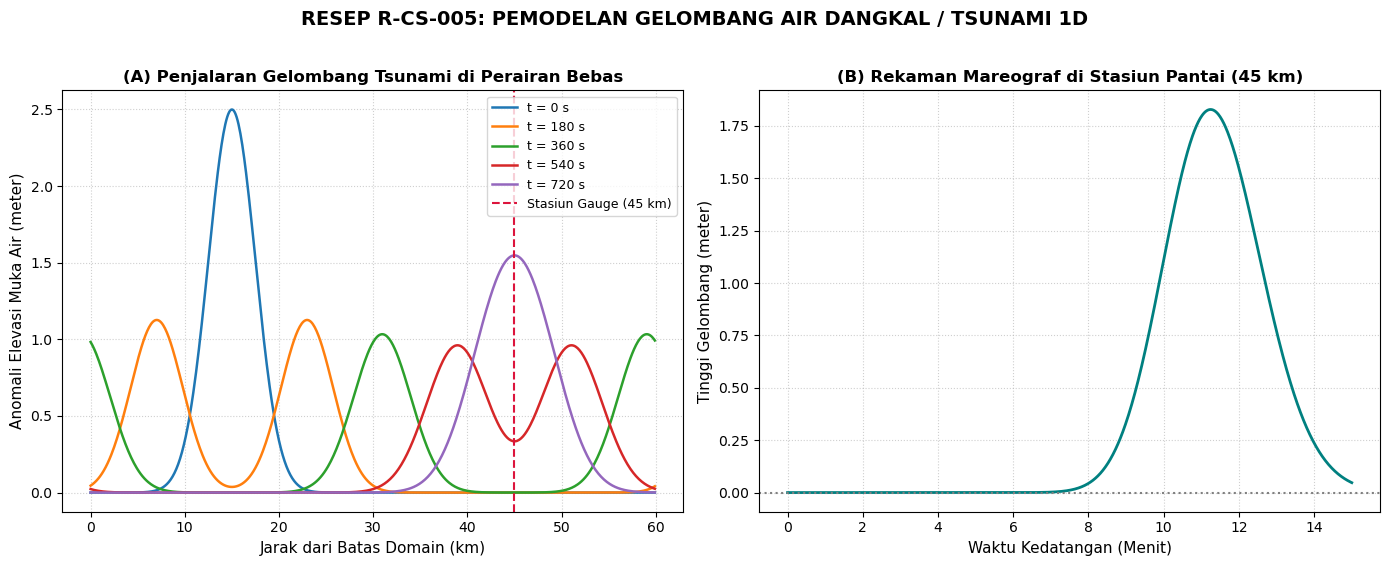

In [3]:
# 5. Visualisasi Hasil Pemodelan Gelombang Tsunami
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot A: Profil Elevasi Gelombang Tsunami pada Berbagai Waktu
for t_snap, wave_profile in snapshots.items():
    axes[0].plot(x / 1000.0, wave_profile, label=f"t = {t_snap} s", linewidth=1.8)
axes[0].axvline(receiver_x_m / 1000.0, color='crimson', linestyle='--', label=f"Stasiun Gauge ({receiver_x_m/1000:.0f} km)")
axes[0].set_title("(A) Penjalaran Gelombang Tsunami di Perairan Bebas", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jarak dari Batas Domain (km)", fontsize=11)
axes[0].set_ylabel("Anomali Elevasi Muka Air (meter)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="upper right", fontsize=9)

# Subplot B: Rekaman Fluktuasi Muka Air di Stasiun Pengamat Pantai
axes[1].plot(np.array(tide_gauge_times) / 60.0, tide_gauge_elevation, color='teal', linewidth=2.0)
axes[1].axhline(0, color='gray', linestyle=':')
axes[1].set_title(f"(B) Rekaman Mareograf di Stasiun Pantai ({receiver_x_m/1000:.0f} km)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Waktu Kedatangan (Menit)", fontsize=11)
axes[1].set_ylabel("Tinggi Gelombang (meter)", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.suptitle("RESEP R-CS-005: PEMODELAN GELOMBANG AIR DANGKAL / TSUNAMI 1D", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### Analisis Resep 3:
- Gelombang deformasi awal terbelah menjadi dua gelombang utama yang merambat ke arah berlawanan dengan kecepatan konstan $c = 44.29\text{ m/s}$ ($159.5\text{ km/jam}$).
- Gelombang yang bergerak ke kanan tiba di stasiun pemantau pantai ($45\text{ km}$) pada menit ke-11.3, menghasilkan lonjakan elevasi muka air yang dapat dijadikan basis peringatan dini tsunami (*Tsunami Early Warning*).

---

## BAGIAN 2: RESEP 4 (`R-GEM-012`)
### Case Study: Diagnostik Gradien Geotermal Berlapis & Upward Heat Flux

#### 1. Latar Belakang Teori Panas Bumi
Dalam eksplorasi panas bumi, bumi tersusun atas lapisan-lapisan batuan dengan nilai konduktivitas termal ($k$) yang berbeda. Berdasarkan Hukum Fourier 1 Dimensi:
$$q_{up} = k_{eff} \cdot \frac{\Delta T}{\Delta z}$$
di mana:
- $\frac{\Delta T}{\Delta z}$ = gradien geotermal ($K/m$ atau $^\circ C/km$)
- $k_{eff}$ = konduktivitas termal efektif dari lapisan batuan ($W/(m\cdot K)$)
- $q_{up}$ = aliran panas konduktif ke arah atas bumi (*upward heat flux*, $W/m^2$ atau $mW/m^2$)

Pada sistem lapisan berlapis, resistansi termal efektif dihitung secara seri:
$$R = \sum_{i} \frac{\Delta z_i}{k_i}, \quad k_{eff} = \frac{\sum \Delta z_i}{R}$$

In [4]:
# 1. Data Lapisan Stratigrafi dan Konduktivitas Termal Batuan
layers_geothermal = [
    {"name": "Lapisan Sedimen Aluvium", "top_m": 0.0, "bottom_m": 500.0, "k": 1.6},      # k = 1.6 W/m.K
    {"name": "Batuan Vulkanik Terubah", "top_m": 500.0, "bottom_m": 1500.0, "k": 2.4},    # k = 2.4 W/m.K
    {"name": "Basement Batuan Beku / Granit", "top_m": 1500.0, "bottom_m": 3000.0, "k": 3.2} # k = 3.2 W/m.K
]

# 2. Data Pengukuran Temperatur Sumur Geotermal (Wellbore Logging Data)
well_observations = [
    {"depth_m": 0.0, "T_c": 27.0},
    {"depth_m": 500.0, "T_c": 52.0},
    {"depth_m": 1000.0, "T_c": 72.0},
    {"depth_m": 1500.0, "T_c": 92.0},
    {"depth_m": 2200.0, "T_c": 113.0},
    {"depth_m": 3000.0, "T_c": 137.0}
]

# 3. Algoritma Diagnostik Gradien dan Heat Flux Berlapis (Piecewise Conductive Diagnostic)
depths = [obs["depth_m"] for obs in well_observations]
temperatures = [obs["T_c"] for obs in well_observations]

diagnostic_results = []

for i in range(len(well_observations) - 1):
    z_top, z_bottom = depths[i], depths[i+1]
    t_top, t_bottom = temperatures[i], temperatures[i+1]
    dz = z_bottom - z_top
    dT = t_bottom - t_top
    
    # Hitung resistansi termal seri pada interval [z_top, z_bottom]
    thermal_resistance = 0.0
    for layer in layers_geothermal:
        overlap = max(0.0, min(z_bottom, layer["bottom_m"]) - max(z_top, layer["top_m"]))
        if overlap > 0:
            thermal_resistance += overlap / layer["k"]
            
    effective_k = dz / thermal_resistance
    gradient_k_per_m = dT / dz
    gradient_c_per_km = gradient_k_per_m * 1000.0
    heat_flux_w_m2 = effective_k * gradient_k_per_m
    heat_flux_mw_m2 = heat_flux_w_m2 * 1000.0
    
    diagnostic_results.append({
        "interval": f"{z_top:.0f} - {z_bottom:.0f} m",
        "mid_depth": (z_top + z_bottom) / 2.0,
        "dz": dz,
        "k_eff": effective_k,
        "gradient_c_km": gradient_c_per_km,
        "heat_flux_mw_m2": heat_flux_mw_m2
    })

print("=== HASIL DIAGNOSTIK GEOTERMAL RESEP R-GEM-012 ===")
print(f"{'Interval Kedalaman':<20} | {'k_eff (W/m.K)':<14} | {'Gradien (°C/km)':<16} | {'Heat Flux (mW/m^2)':<18}")
print("-" * 75)
for r in diagnostic_results:
    print(f"{r['interval']:<20} | {r['k_eff']:<14.2f} | {r['gradient_c_km']:<16.2f} | {r['heat_flux_mw_m2']:<18.2f}")

=== HASIL DIAGNOSTIK GEOTERMAL RESEP R-GEM-012 ===
Interval Kedalaman   | k_eff (W/m.K)  | Gradien (°C/km)  | Heat Flux (mW/m^2)
---------------------------------------------------------------------------
0 - 500 m            | 1.60           | 50.00            | 80.00             
500 - 1000 m         | 2.40           | 40.00            | 96.00             
1000 - 1500 m        | 2.40           | 40.00            | 96.00             
1500 - 2200 m        | 3.20           | 30.00            | 96.00             
2200 - 3000 m        | 3.20           | 30.00            | 96.00             


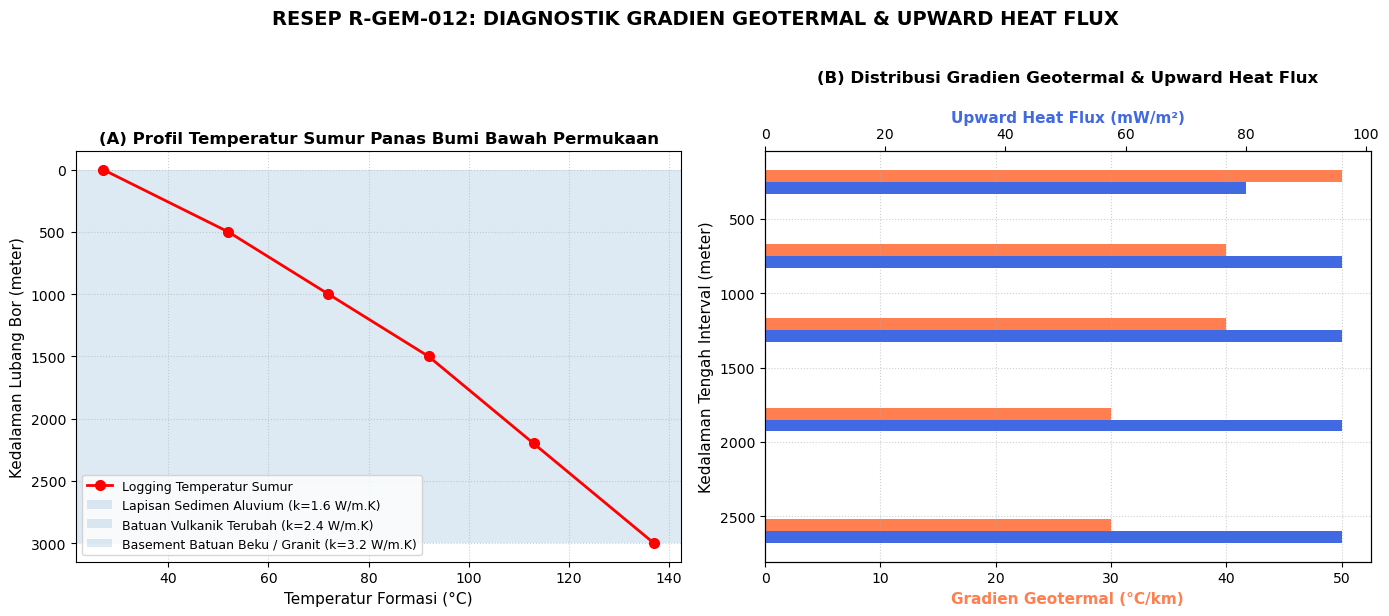

In [5]:
# 4. Visualisasi Profil Temperatur & Gradien Termal Geotermal
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot A: Kurva Profil Temperatur vs Kedalaman dengan Batas Formasi
axes[0].plot(temperatures, depths, 'ro-', linewidth=2.0, markersize=7, label="Logging Temperatur Sumur")
for layer in layers_geothermal:
    axes[0].axhspan(layer["top_m"], layer["bottom_m"], alpha=0.15, label=f"{layer['name']} (k={layer['k']} W/m.K)")
axes[0].invert_yaxis()
axes[0].set_title("(A) Profil Temperatur Sumur Panas Bumi Bawah Permukaan", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Temperatur Formasi (°C)", fontsize=11)
axes[0].set_ylabel("Kedalaman Lubang Bor (meter)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="lower left", fontsize=9)

# Subplot B: Bar Chart Gradien Geotermal dan Heat Flux
mid_depths = [r["mid_depth"] for r in diagnostic_results]
gradients = [r["gradient_c_km"] for r in diagnostic_results]
fluxes = [r["heat_flux_mw_m2"] for r in diagnostic_results]

ax_grad = axes[1]
bars1 = ax_grad.barh([m - 40 for m in mid_depths], gradients, height=80, color='coral', label="Gradien Geotermal (°C/km)")
ax_flux = ax_grad.twiny()
bars2 = ax_flux.barh([m + 40 for m in mid_depths], fluxes, height=80, color='royalblue', label="Aliran Panas (mW/m²)")

ax_grad.invert_yaxis()
ax_grad.set_xlabel("Gradien Geotermal (°C/km)", color='coral', fontsize=11, fontweight="bold")
ax_flux.set_xlabel("Upward Heat Flux (mW/m²)", color='royalblue', fontsize=11, fontweight="bold")
ax_grad.set_ylabel("Kedalaman Tengah Interval (meter)", fontsize=11)
ax_grad.set_title("(B) Distribusi Gradien Geotermal & Upward Heat Flux", fontsize=12, fontweight="bold", pad=20)
ax_grad.grid(True, linestyle=":", alpha=0.6)

plt.suptitle("RESEP R-GEM-012: DIAGNOSTIK GRADIEN GEOTERMAL & UPWARD HEAT FLUX", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### Analisis Resep 4:
- Pada lapisan atas (sedimen aluvium dengan $k$ rendah = $1.6\text{ W/m}\cdot\text{K}$), gradien suhu paling terjal mencapai $50^\circ\text{C/km}$ karena batuan bertindak sebagai tudung penutup (*caprock* / isolator termal).
- Pada formasi basement kristalin dengan konduktivitas tinggi ($k = 3.2\text{ W/m}\cdot\text{K}$), gradien termal berkisar $30^\circ\text{C/km}$ namun nilai *upward heat flux* tetap stabil di kisaran $80 - 96\text{ mW/m}^2$, mengindikasikan adanya prospek anomali aliran panas bumi dari reservoir yang dalam.